# Chapitre 10 - Cours 2 : fonctions de perte, robustesse et gradient boosting

Ce notebook couvre les sections 10.6 à 10.12 du livre :

1. les **fonctions de perte** pour la classification et la régression, et leur
   **robustesse** (figures 10.4 et 10.5) ;
2. le **boosting d'arbres** (section 10.9) ;
3. le **gradient boosting** (algorithme 10.3, « MART ») et les gradients usuels (tableau 10.2) ;
4. la **taille des arbres** et les interactions (figures 10.9 et 10.10) ;
5. la **régularisation** : rétrécissement (*shrinkage*, figure 10.11) et sous-échantillonnage
   (figure 10.12).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl.ch10_boosting import (
    AdaBoostM1, GradientBoosting, RegressionTree, simulate_nested_spheres,
    loss_misclassification, loss_exponential, loss_binomial_deviance,
    loss_squared_margin, loss_hinge, loss_huber)

## 1. Pertes pour la classification : la marge

Avec $y \in \{-1,+1\}$ et une fonction réelle $f$ dont le signe donne la classe prédite,
la quantité clé est la **marge** $y\,f(x)$ :

- $y f(x) > 0$ : observation bien classée ; plus la marge est grande, plus on est « sûr » ;
- $y f(x) < 0$ : observation mal classée.

Une bonne perte de classification doit pénaliser les marges négatives bien plus que les
marges positives (déjà correctes). Toutes les pertes ci-dessous s'écrivent comme une
fonction de la marge seule.

Les pertes de la figure 10.4 (chacune normalisée pour passer par le point $(0,1)$) :

| perte | expression en fonction de $m = yf$ |
|---|---|
| mauvaise classification | $I(m < 0)$ |
| exponentielle (10.8) | $e^{-m}$ |
| déviance binomiale (10.18) | $\log(1+e^{-2m}) / \log 2$ |
| quadratique | $(y-f)^2 = (1-m)^2$ (car $y^2=1$) |
| « support vector » (chap. 12) | $(1-m)_+ = \max(0, 1-m)$ |

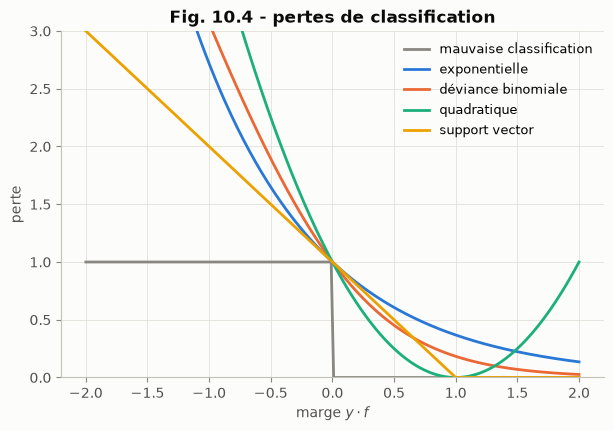

In [2]:
m = np.linspace(-2, 2, 401)
plt.figure(figsize=(7, 4.5))
plt.plot(m, loss_misclassification(m), color=GRAY, label="mauvaise classification")
plt.plot(m, loss_exponential(m), color=COLORS[0], label="exponentielle")
plt.plot(m, loss_binomial_deviance(m), color=COLORS[1], label="déviance binomiale")
plt.plot(m, loss_squared_margin(m), color=COLORS[2], label="quadratique")
plt.plot(m, loss_hinge(m), color=COLORS[3], label="support vector")
plt.ylim(0, 3)
plt.title("Fig. 10.4 - pertes de classification")
plt.xlabel("marge $y\\cdot f$")
plt.ylabel("perte")
plt.legend()
plt.show()

Lecture de la figure :

- exponentielle et déviance sont des approximations **continues et décroissantes** de la
  perte 0-1 ; pour des marges très négatives, la déviance croît **linéairement** (comme $-2m/\log 2$)
  alors que l'exponentielle croît **exponentiellement** ;
- la perte quadratique n'est pas monotone : au-delà de $m=1$ elle **augmente** et pénalise
  donc des observations très bien classées. C'est pourquoi elle convient mal à la classification ;
- la perte « support vector » est nulle dès que $m \ge 1$ (cf. chapitre 12).